# Where should this stock portfolio be held? A tax story in pictures

The same stock-picking rule earns the same return **before tax** wherever you keep it. What changes is the tax. This notebook shows, with charts, what the account (taxable, TFSA, RRSP) and your tax bracket do to the growth of one dividend portfolio, always next to the **passive index taxed in exactly the same way**.

There is no Monte Carlo here and no forecasting: one run of the history of a **made-up Canadian market** (so everything works offline), taxed under different assumptions. The numbers show how the machinery behaves, not what you will earn.

1. **The accounts.** Growth before and after tax, the tax paid each year, and the "tax drag" in points of growth per year.
2. **The RRSP convention.** Why the RRSP result depends on the rate you assume at withdrawal and on how long the money stays in.
3. **The bracket.** What your income and your province do to the tax rates, and to the same portfolio.
4. **A reading guide**: what to conclude, and what is left out.

Not tax advice. Nothing is written to disk and nothing leaves your machine. About 30 seconds to run.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.research import tax_plots as tp

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
NAME = tp.ACCOUNT_NAME                    # taxable -> Taxable, tfsa -> TFSA, rrsp -> RRSP

def tax_config(province="AB", other_income=90_000, rrsp_rate=0.30):
    # other_income: what you earn from work each year; it sets the bracket the portfolio's income is stacked on
    return TaxConfig(model=CanadianTax(province, other_income=other_income), account="taxable", rrsp_withdrawal_rate=rrsp_rate)

def show(fig):
    display(fig); plt.close(fig)

## 1. One portfolio, three accounts

`stable_dividend` is one of the Globe and Mail screens: companies that pay a dividend and keep paying it. It is run on the synthetic Canadian market (150 stocks, 12 years), rebalanced once a year, **Alberta** resident with **$90,000** of other income a year, and an RRSP withdrawn at a **30%** tax rate. `account_compare` runs the identical portfolio and the passive index under each account and keeps the yearly tax tables.

In [2]:
lab = Lab.synthetic(freq="ME", n_stocks=150, years=12, seed=3)
rep = lab.account_compare(["stable_dividend"], tax=tax_config(), rebalance_months=12)
print(rep.data_card.line())

PICKS, INDEX = "stable_dividend", rep.benchmark          # INDEX is the passive index of this market
def pair(account):
    r = rep.reports[account]
    return {"stable_dividend": r.results[PICKS], "index (" + INDEX + ")": tp.index_result(r)}

Data: synthetic, 2000-01-31..2011-12-31, 150 names, benchmark SYN_CAPWT (total_return), PIT yes, delisted yes (33), survivorship -2.4%/yr


### Growth before and after tax

Each panel is one account. **Thin pale line: growth before tax. Thick line: growth after tax.** Blue is the dividend portfolio; the grey dashed line is the passive index taxed the same way. The vertical scale is logarithmic, so a straight climb means a steady yearly growth rate; the number at the right edge is the final multiple of the starting money.

* **Taxable:** the thick line sits slightly below the pale one: dividends and gains are taxed along the way.
* **TFSA:** the two lines coincide: nothing is taxed.
* **RRSP:** nothing is taxed until the last day, when the whole balance is taxed as income (the drop at the right edge). Both the portfolio and the index drop.

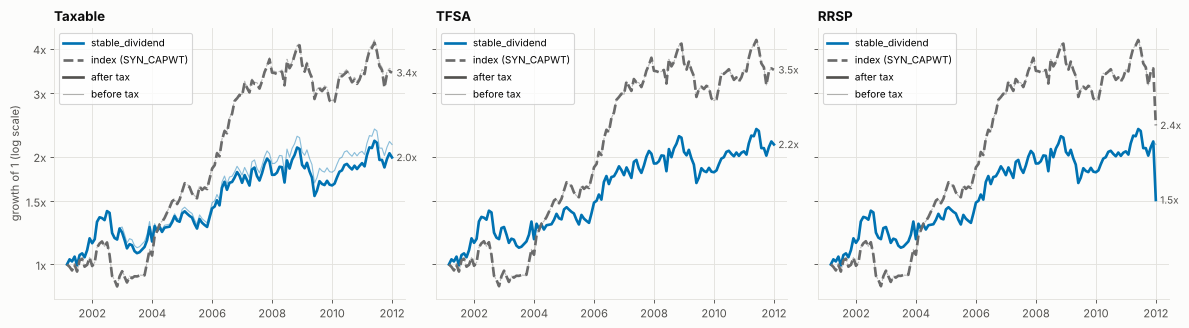

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    tp.after_tax_curves(pair(a), ax=ax, title=NAME[a])
for ax in axs[1:]:
    ax.set_ylabel("")
fig.tight_layout(); show(fig)

### Tax paid, year by year

The bars are dollars of tax in each year on a $100,000 start, split by what was taxed: **dividends**, **interest**, **capital gains** (when the portfolio sells at a profit), **foreign dividends** and, for the RRSP, the **withdrawal**. A negative bar is a refund of an earlier year's tax from a loss carried back. This portfolio is all Canadian, so there is no foreign withholding to lose here (the notebook on foreign holdings covers that).

The shapes differ more than the totals suggest: a taxable account pays a little every year, a TFSA pays nothing, an RRSP pays everything at once, at the end.

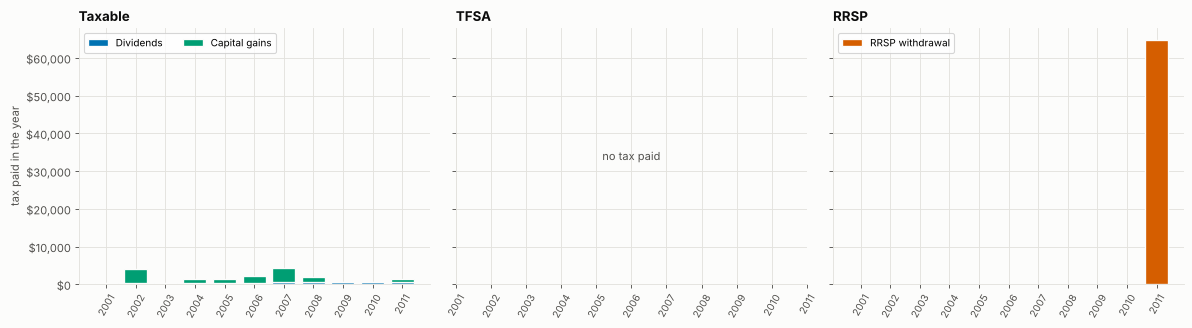

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    tp.tax_paid_stack(rep.reports[a].results[PICKS], ax=ax, title=NAME[a])
for ax in axs[1:]:
    ax.set_ylabel("")
fig.tight_layout(); show(fig)

### The tax drag, in points of growth a year

**Tax drag** is growth per year before tax minus growth per year after tax. Pale bar: before tax. Dark bar: after tax. The bold number is the drag. The pair for the index sits beside the pair for the portfolio, in each account.

What to look for: the **TFSA** has no drag by construction. The **taxable** drag is small for a portfolio that holds its winners and large for one that sells a lot. The **RRSP** drag looks big because the whole balance is taxed at the end; the next section shows how much of that is just the assumed rate and the length of the run.

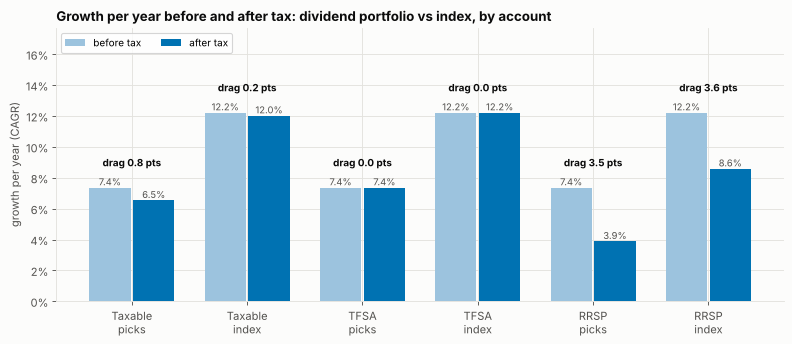

,CAGR,AfterTaxCAGR,TaxDrag/yr,AfterTaxExcess/yr
label,,,,
Taxable picks,7.37%,6.55%,0.82%,-5.48%
Taxable index,12.22%,12.03%,0.20%,-
TFSA picks,7.37%,7.37%,0.00%,-4.86%
TFSA index,12.22%,12.22%,0.00%,-
RRSP picks,7.37%,3.89%,3.48%,-4.70%
RRSP index,12.22%,8.59%,3.63%,-


In [5]:
t = rep.table.copy()
t["label"] = t["account"].map(NAME) + "\n" + np.where(t["kind"] == "index", "index", "picks")
order = [f"{NAME[a]}\n{k}" for a in ACCOUNTS for k in ("picks", "index")]
t = t.set_index("label").loc[order].reset_index()
fig, ax = plt.subplots(figsize=(10, 4.4))
tp.tax_drag_bars(t, ax=ax, title="Growth per year before and after tax: dividend portfolio vs index, by account")
fig.tight_layout(); show(fig)
t[["label", "CAGR", "AfterTaxCAGR", "TaxDrag/yr", "AfterTaxExcess/yr"]].assign(label=t["label"].str.replace("\n", " ")).set_index("label").style.format("{:.2%}", na_rep="-")

## 2. The RRSP: the answer depends on two things you supply

In this model the RRSP is **tax-deferred**: nothing is taxed while the money stays in, and on the last day the *whole balance* is taxed as ordinary income at one rate you choose (`rrsp_withdrawal_rate`). The deduction you get for putting money in (the refund) is **not** modelled, so the principal you contributed is taxed on the way out without ever having been credited on the way in. That is conservative for the RRSP, and it is why the RRSP can look bad here even when it is a good idea in real life; the reading guide at the end comes back to it.

### How much does the assumed withdrawal rate matter?

Lines show after-tax growth per year. The taxable lines are flat because the withdrawal rate does not touch them; the RRSP lines fall as the rate rises. In this run no RRSP line reaches its taxable twin, even at a 20% withdrawal rate: with no deduction refund modelled the RRSP loses to the taxable account at every rate shown. Where such a line did cross, that would be the withdrawal rate at which you would be indifferent, in this model.

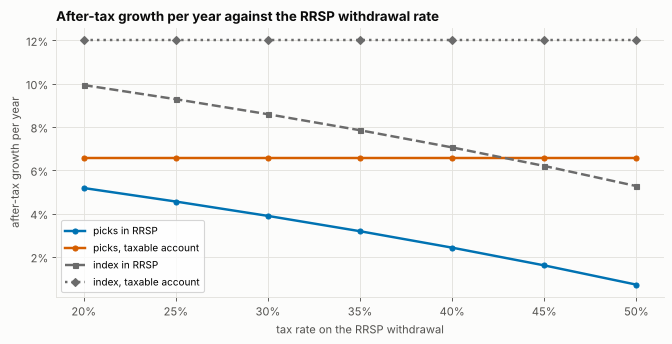

In [6]:
rates = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
rows = []
for r in rates:
    x = lab.account_compare([PICKS], tax=tax_config(rrsp_rate=r), rebalance_months=12, accounts=["taxable", "rrsp"]).table
    g = x.set_index(["kind", "account"])["AfterTaxCAGR"]
    rows.append({"rate": r, "picks in RRSP": g[("portfolio", "rrsp")], "picks taxable": g[("portfolio", "taxable")],
                 "index in RRSP": g[("index", "rrsp")], "index taxable": g[("index", "taxable")]})
by_rate = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
tp.sensitivity_lines(by_rate, "rate", {"picks in RRSP": "picks in RRSP", "picks taxable": "picks, taxable account",
                     "index in RRSP": "index in RRSP", "index taxable": "index, taxable account"}, ax=ax,
                     title="After-tax growth per year against the RRSP withdrawal rate",
                     xlabel="tax rate on the RRSP withdrawal", ylabel="after-tax growth per year")
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
fig.tight_layout(); show(fig)

### How much does the length of the holding matter?

Same portfolio, same 30% at withdrawal, but the run is cut to the **last 3, 5, 8 and 11 years** of the data. The chart shows the **tax drag** (growth per year lost to tax) in each account.

**Why short windows punish the RRSP.** The withdrawal tax is a one-time bite out of the whole balance: with 30% that is a loss of about `-ln(0.70) = 36%` of the final value, whatever the length of the run. Spread over 3 years it costs about 11 points of growth a year; spread over 11 years, 3 to 4 points. The taxable account's tax is paid a little at a time and does not care about the length in the same way. So the RRSP is a long-horizon tool in this model, and a short run is exactly where the missing deduction refund matters most.

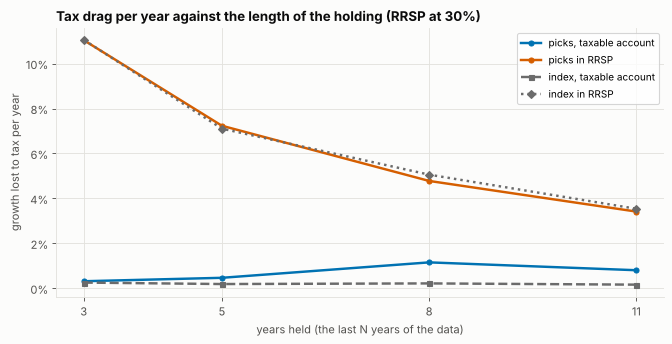

In [7]:
end = rep.reports["taxable"].benchmark.index[-1]
rows = []
for years in (3, 5, 8, 11):
    start = str((end - pd.DateOffset(years=years)).date())
    x = lab.account_compare([PICKS], tax=tax_config(), rebalance_months=12, start=start).table
    g = x.set_index(["kind", "account"])["TaxDrag/yr"]
    rows.append({"years": years, "picks, taxable": g[("portfolio", "taxable")], "picks, RRSP": g[("portfolio", "rrsp")],
                 "index, taxable": g[("index", "taxable")], "index, RRSP": g[("index", "rrsp")]})
by_years = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
tp.sensitivity_lines(by_years, "years", {"picks, taxable": "picks, taxable account", "picks, RRSP": "picks in RRSP",
                     "index, taxable": "index, taxable account", "index, RRSP": "index in RRSP"}, ax=ax,
                     title="Tax drag per year against the length of the holding (RRSP at 30%)",
                     xlabel="years held (the last N years of the data)", ylabel="growth lost to tax per year")
ax.set_xticks(by_years["years"])
fig.tight_layout(); show(fig)

## 3. The bracket: what your income and province do

Tax rates depend on the **bracket**: the more other income you have, the higher the rate on the next dollar. The kinds of income are not taxed alike. The chart shows the tax on the **next $1** of each kind, stacked on top of other income, for Alberta (solid) and British Columbia (dashed).

* **Ordinary income** (salary, interest, an RRSP withdrawal) is taxed the most.
* **Non-eligible dividends** come next; **eligible dividends** (the usual ones from large Canadian companies) carry a credit that makes them far cheaper, and at lower incomes the rate can even be **negative**: the credit is larger than the tax. The black line is zero.
* **Capital gains** are half-taxed: about half the ordinary rate.

The steps are the brackets, and the flat stretch after about $260,000 is the top bracket. Very low incomes (under about $30,000) are left off the vertical scale because there is little tax to measure.

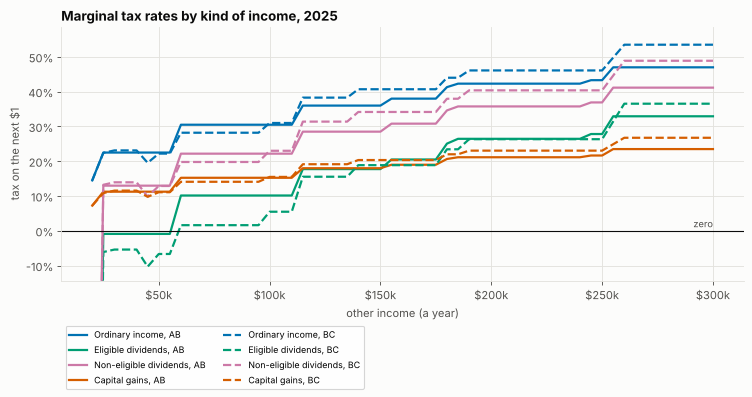

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
tp.marginal_rate_curves(("AB", "BC"), 2025, range(20_000, 300_001, 5_000), ax=ax)
fig.tight_layout(); show(fig)

### The same portfolio at three incomes in two provinces

Taxable account only (the TFSA pays no tax and the RRSP depends on the withdrawal rate, not on your bracket today). Other income of **$30,000, $90,000 and $200,000** a year, Alberta and British Columbia, the portfolio and the passive index each time. A higher bracket takes more of the dividends and gains, so after-tax growth falls as income rises, for the portfolio and the index alike; the gap between the two is the question of whether the portfolio's way of earning (dividends, selling) is taxed more heavily than the index's.

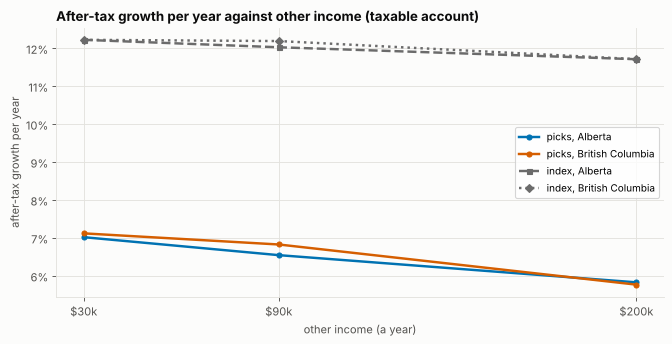

province,other_income,picks,index,gap
AB,"$30,000",7.02%,12.22%,-5.20%
AB,"$90,000",6.55%,12.03%,-5.48%
AB,"$200,000",5.83%,11.71%,-5.88%
BC,"$30,000",7.12%,12.22%,-5.10%
BC,"$90,000",6.83%,12.19%,-5.36%
BC,"$200,000",5.77%,11.72%,-5.95%


In [9]:
rows = []
for prov in ("AB", "BC"):
    for inc in (30_000, 90_000, 200_000):
        x = lab.account_compare([PICKS], tax=tax_config(prov, inc), rebalance_months=12, accounts=["taxable"]).table.set_index("kind")["AfterTaxCAGR"]
        rows.append({"province": prov, "other_income": inc, "picks": x["portfolio"], "index": x["index"]})
by_bracket = pd.DataFrame(rows)
wide = by_bracket.pivot(index="other_income", columns="province", values=["picks", "index"])
wide.columns = [f"{k} {p}" for k, p in wide.columns]
wide = wide.reset_index()
fig, ax = plt.subplots(figsize=(8.5, 4.4))
tp.sensitivity_lines(wide, "other_income", {"picks AB": "picks, Alberta", "picks BC": "picks, British Columbia",
                     "index AB": "index, Alberta", "index BC": "index, British Columbia"}, ax=ax,
                     title="After-tax growth per year against other income (taxable account)",
                     xlabel="other income (a year)", ylabel="after-tax growth per year")
ax.set_xticks(wide["other_income"], ["$30k", "$90k", "$200k"])
fig.tight_layout(); show(fig)
by_bracket.assign(gap=lambda d: d["picks"] - d["index"]).style.format({"other_income": "${:,.0f}", "picks": "{:.2%}", "index": "{:.2%}", "gap": "{:+.2%}"}).hide(axis="index")

## 4. How to read this

* **The account matters more than a few points of selection skill.** Before tax the portfolio is the same everywhere; the TFSA keeps all of it, the taxable account gives some back every year, the RRSP gives back a large block on the last day. The drag bars put numbers on it for this portfolio and for the index next to it.
* **Compare with the index in the same account.** The passive index is taxed the same way (it pays dividends too, and it is assumed to be bought and held). In this synthetic run the portfolio trails the index before tax and still trails it after tax; a portfolio that is ahead before tax can fall behind after tax if it pays more dividends or sells more.
* **The RRSP result is an assumption, not a finding.** Change the withdrawal rate or the length of the holding and its place in the ranking moves, as the two sensitivity charts show. Short holdings are where it looks worst.
* **The bracket changes the order of kinds of income.** Dividends from Canadian companies are cheap at low incomes (even negative), capital gains are always about half the ordinary rate, and interest and RRSP withdrawals are taxed the most.

### What this ignores

* **Contribution room.** A TFSA or RRSP holds only what the room allows. Each account here is given all the money in turn.
* **The RRSP deduction refund.** The tax saved when you contribute is not modelled. It is the main reason an RRSP wins for someone in a higher bracket now than at retirement, and it is why the RRSP looks too weak here, especially over short periods. Modelling it needs your contribution amounts and your bracket in each year, which this notebook does not assume.
* **AMT, benefit clawbacks, the age credit, pension splitting** and the interaction of withdrawals with OAS are not in the model.
* **Tax tables.** Only the 2025 tables exist; every year of the run uses them (the operation says so). Alberta numbers are the owner's reference; the **British Columbia constants are partly marked UNVERIFIED** in `tax_ca/tables.py` (the non-eligible dividend credit rate, the absence of a surtax or health premium, a possible change for 2026): treat BC differences from Alberta as indicative.
* **The data.** A synthetic Canadian market: the level of any return is meaningless; only the comparison between accounts and brackets is.
* **Not tax advice.** Check figures against the CRA and provincial sources for the year.